# Variational inference by computation
## From a noisy sensor to Bayesian neural networks
**ELG 5218 · Miodrag Bolic · University of Ottawa**

This notebook accompanies the 19-slide deck `VI_Computational_Slides_Short.tex`. Entropy, KL and the ELBO derivation come from the previous (theory) lecture. We use natural logarithms and report ELBO/KL values in nats.

**One pipeline, three problems.** Every section implements a step of the same computation (slide 2):

> **Model** $\log p(x,z)$ → **Family** $q_\lambda$, $\lambda=(\mu,r)$ → **Sample** $z=\mu+e^{r}\epsilon$ → **Estimate** $\widehat{\mathcal L}$ → **Gradient** (autodiff) → **Update** (Adam) → repeat → **Use** samples of $q$.

Only the **Model** step changes between the sensor, the nonlinear sensor, linear regression and the Bayesian neural network.

| Section | Slides | Pipeline step |
|---|---|---|
| §1 What do we want to infer? | 3–4 | Model |
| §2 A Gaussian with adjustable centre and spread | 4, 6 | Family |
| §3 The ELBO as a computable score | 5–6 | Estimate (exact diagnostic) |
| §4 Differentiable sampling and the loss | 7–8 | Sample, Estimate, Gradient |
| §5 Fit, inspect, and use | 9–11 | Update, Use |
| §6 A new likelihood | 12 | Model (only change) |
| §7 Minibatches (optional) | 15 | Estimate |
| §8 Regression weights | 13–14 | Model, Family |
| §9 Bayesian neural network | 14–16 | all steps |
| §10 Check understanding | 17 | |

Figures are written to `figures1/` (the folder the slides read); the ELBO table for slide 6 is written to `figures1/elbo_table.tex`.

**Main VI class:** §§1–6, then the regression bridge in §8 and the core questions in §10. **Optional minibatching and next BNN class:** §§7 and 9. All cells still run in order with Run All.

**Run:** Python 3.10+ with NumPy, Matplotlib, PyTorch and IPython. Install with `%pip install numpy matplotlib torch ipython` if needed, restart the kernel and run all cells. No external dataset or GPU is needed. Embedded animations have play/pause, a frame slider and single-step controls. If a preview suppresses scripts, open the notebook in Jupyter and rerun the cells.

**Teaching goal:** identify what is unknown, what the optimizer adjusts, how the ELBO judges improvement, and how posterior samples answer a question.

Colour convention: gray = prior, black dashed = teaching reference, blue = variational distribution/function uncertainty, orange = observations or the KL gap. Exact and grid reference posteriors never enter training.


In [1]:
import math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import torch
from torch.distributions import Normal

torch.set_default_dtype(torch.float64)
torch.set_num_threads(1)
torch.manual_seed(7)
np.random.seed(7)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'animation.embed_limit': 60})
ASSETS = Path('figures1'); ASSETS.mkdir(exist_ok=True)   # same folder as the slides' \includegraphics{figures1/...}
BLUE, ORANGE, GRAY = '#2463A6', '#C66B20', '#88929D'
def savefig(name):
    plt.savefig(ASSETS / (name + '.png'), dpi=160, bbox_inches='tight')
def play(fig, update, frames):
    animation = FuncAnimation(fig, update, frames=frames, interval=220, blit=False)
    html = animation.to_jshtml(default_mode='once')
    plt.close(fig)
    display(HTML(html))
def reveal(question, answer):
    display(HTML(f'<details><summary><b>{question}</b></summary><p>{answer}</p></details>'))
def pdf(grid, mu, sd):
    return np.exp(-0.5*((grid-mu)/sd)**2)/(np.sqrt(2*np.pi)*sd)
print('PyTorch', torch.__version__, '| CPU | float64')

PyTorch 2.11.0+cpu | CPU | float64


## 1. What do we want to infer? · Slides 3–4 · *Pipeline: Model*
A sensor measures a fixed unknown quantity $z$. Its readings satisfy $x_n=z+\epsilon_n$, with independent $\epsilon_n\sim\mathcal N(0,\sigma_\epsilon^2)$. We specify a prior $z\sim\mathcal N(0,1)$ and known sensor noise $\sigma_\epsilon=0.6$.

Our target is $p(z\mid\mathbf x)$. Eventually we want a credible interval and the probability that $z>1$. A future reading also contains sensor noise, so its predictive interval will be wider.

The readings below are fixed teaching data. Neither it nor the exact posterior enters the optimizer.

**Pause and predict (slide 4):** if we collect another reading, which of these change: $\mathbf x$, $\sigma_\epsilon$, $p(z)$, the posterior, $\lambda$, the draws $\epsilon$?

<details><summary>Answer</summary>The data (now 7 readings), the posterior (sd 0.238 → 0.221; the mean moves toward the new reading) and therefore λ after re-fitting. The noise level, the prior and the code stay the same; ε is drawn fresh at every step anyway.</details>

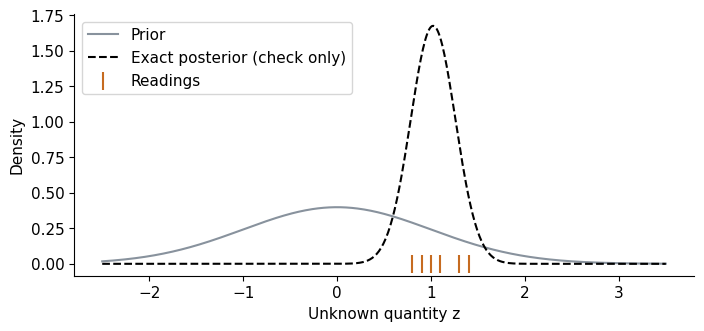

Check: posterior mean=1.0220, SD=0.2379


In [2]:
x_obs = torch.tensor([0.8, 1.1, 1.4, 0.9, 1.3, 1.0])   # sensor readings x_n
noise_sd = 0.6
prior = Normal(torch.tensor(0.), torch.tensor(1.))
N = len(x_obs)
exact_var = 1 / (1 + N/noise_sd**2)
exact_mu = float(x_obs.sum()/noise_sd**2 * exact_var)
exact_sd = math.sqrt(exact_var)
grid = np.linspace(-2.5, 3.5, 500)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(grid, pdf(grid, 0, 1), color=GRAY, label='Prior')
ax.plot(grid, pdf(grid, exact_mu, exact_sd), 'k--', label='Exact posterior (check only)')
ax.scatter(x_obs.numpy(), np.zeros(N), color=ORANGE, marker='|', s=180, label='Readings')
ax.set(xlabel='Unknown quantity z', ylabel='Density'); ax.legend()
savefig('sensor'); plt.show()
print(f'Check: posterior mean={exact_mu:.4f}, SD={exact_sd:.4f}')

## 2. A Gaussian with adjustable centre and spread · Slides 4, 6 · *Pipeline: Family*
Choose $q(z)=\mathcal N(z;\mu,\sigma^2)$. For now adjust the centre $\mu$ and spread $\sigma$ directly. We will introduce a numerical parameterization that keeps $\sigma>0$ when we write the optimizer.

The physical unknown is $z$. The approximation parameters describe our uncertainty about it.

**Animation:** move the centre while holding the spread fixed, then change the spread. This is a prescribed sweep, not optimization. Pause and ask: which change makes more of q overlap the plausible region?

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(grid, pdf(grid, exact_mu, exact_sd), 'k--', label='Reference posterior')
line, = ax.plot([], [], color=BLUE, lw=2.5, label='Adjustable q')
ax.set(xlim=(-2.5, 3.5), ylim=(0, 2), xlabel='z', ylabel='Density'); ax.legend()
sequence = [(m, 0.8) for m in np.linspace(-0.8, exact_mu, 12)]
sequence += [(exact_mu, s) for s in np.linspace(0.8, exact_sd, 12)]
def adjust_q(k):
    m, s = sequence[k]; line.set_data(grid, pdf(grid,m,s))
    ax.set_title(f'Parameter sweep: mean={m:.2f}, SD={s:.2f}')
play(fig, adjust_q, len(sequence))
reveal('Is q the prior?', 'No. The prior is part of the specified model. q is the distribution we fit to approximate the posterior after seeing the data.')

### Why both the centre and the spread matter · Slide 6
Before displaying objective values, predict which q is better: wrong centre, correct centre but excessive spread, or a very narrow distribution. Then compare with the matched-reference case. A higher density peak does not by itself imply a better posterior approximation.

The next helper evaluates the exact objective for this Gaussian benchmark. It is separate from the training loss used later.

**Pause and predict (slide 6):** why is the narrowest Gaussian, with the tallest peak, not the best one? The cell also writes `figures1/elbo_table.tex` for the slide.

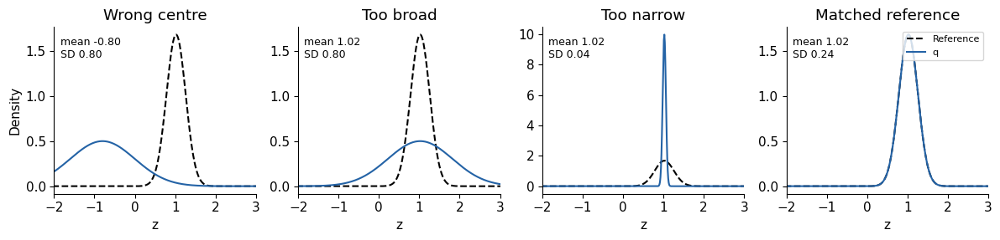

Fixed log evidence = -4.8108 nats
Wrong centre         mean=-0.800, SD=0.800, ELBO=-38.076, KL=33.265
Too broad            mean=1.022, SD=0.800, ELBO=-8.751, KL=3.941
Too narrow           mean=1.022, SD=0.040, ELBO=-6.108, KL=1.297
Matched reference    mean=1.022, SD=0.238, ELBO=-4.811, KL=0.000


In [4]:
def elbo_diagnostics(mu, sd):
    # Teaching diagnostic only. The optimizer below still uses sampled gradients.
    if sd <= 0: raise ValueError('Standard deviation must be positive')
    expected_ll = (-N/2*np.log(2*np.pi*noise_sd**2)
                   -(np.sum((x_obs.numpy()-mu)**2)+N*sd**2)/(2*noise_sd**2))
    expected_prior = -.5*np.log(2*np.pi)-.5*(mu**2+sd**2)
    entropy = .5*np.log(2*np.pi*np.e*sd**2)
    elbo = expected_ll + expected_prior + entropy
    posterior_kl = .5*((sd**2+(mu-exact_mu)**2)/exact_var-1+np.log(exact_var/sd**2))
    return dict(mu=float(mu),sd=float(sd),log_likelihood=float(expected_ll),
                log_prior=float(expected_prior),entropy=float(entropy),
                elbo=float(elbo),kl=float(posterior_kl),loss=float(-elbo))
# Evidence from the marginal data distribution, independent of the fitted q.
sum_x=float(x_obs.sum()); sum_x2=float(x_obs.square().sum())
logdet=(N-1)*np.log(noise_sd**2)+np.log(noise_sd**2+N)
quadratic=sum_x2/noise_sd**2-sum_x**2/(noise_sd**2*(noise_sd**2+N))
log_evidence=-.5*(N*np.log(2*np.pi)+logdet+quadratic)
candidates=[('Wrong centre',-.8,.8),('Too broad',exact_mu,.8),
            ('Too narrow',exact_mu,.04),('Matched reference',exact_mu,exact_sd)]
candidate_rows=[{'name':name,**elbo_diagnostics(mu,sd)} for name,mu,sd in candidates]
fig,axes=plt.subplots(1,4,figsize=(12,3.0),sharex=True)
for ax,row in zip(axes,candidate_rows):
    ax.plot(grid,pdf(grid,exact_mu,exact_sd),'k--',label='Reference')
    ax.plot(grid,pdf(grid,row['mu'],row['sd']),color=BLUE,label='q')
    ax.set(xlim=(-2,3),xlabel='z',title=row['name'])
    ax.text(.03,.94,f"mean {row['mu']:.2f}\nSD {row['sd']:.2f}",
            transform=ax.transAxes,va='top',fontsize=9)
axes[0].set_ylabel('Density');axes[-1].legend(fontsize=8,loc='upper right')
fig.tight_layout();savefig('q_candidates');plt.show()
print(f'Fixed log evidence = {log_evidence:.4f} nats')
for row in candidate_rows:
    print(f"{row['name']:20s} mean={row['mu']:.3f}, SD={row['sd']:.3f}, ELBO={row['elbo']:.3f}, KL={row['kl']:.3f}")
    assert abs(log_evidence-row['elbo']-row['kl'])<1e-10
import json
(ASSETS/'elbo_values.json').write_text(json.dumps({'log_evidence':float(log_evidence),'rows':candidate_rows},indent=2))
# LaTeX table used by slide 6 (\input{figures1/elbo_table.tex})
table_rows='\n'.join(f"{r['name']} & ${r['mu']:.3f}$ & {r['sd']:.3f} & ${r['elbo']:.3f}$ & {r['kl']:.3f}\\\\" for r in candidate_rows)
(ASSETS/'elbo_table.tex').write_text(
    '\\begin{center}\n\\begin{tabular}{@{}lrrrr@{}}\n\\toprule\n'
    'Approximation & Mean & SD & ELBO & Posterior KL\\\\\\midrule\n'
    + table_rows + '\\bottomrule\n\\end{tabular}\n\n\\smallskip\n'
    + f'Fixed $\\log p(\\mathbf x)={log_evidence:.3f}$ nats.\n\\end{{center}}\n')
reveal('Why is the narrowest Gaussian, with the tallest peak, not the best one? (slide 6)',
       'The narrow q has the best fit term (all samples at the likelihood peak), but its entropy is about 1.8 nats lower than the matched q, '
       'so its ELBO is 1.3 nats lower. A taller peak only means a narrower distribution: it claims more certainty than the data justify, '
       'e.g. P(z>1) = 0.71 instead of 0.54. Compare the log_likelihood, log_prior and entropy entries printed above.')


## 3. The ELBO as a computable score · Slides 5–6 · *Pipeline: Estimate (exact diagnostic)*
The ELBO was derived in the theory lecture; here we only *compute* it. The model and observations stay fixed. Improving q raises the ELBO toward the fixed log evidence. The vertical gap is the posterior KL. **Increase ELBO; decrease KL and the negative-ELBO loss.**

The following plot uses exact diagnostics for this toy model. Its purpose is to show the bound clearly without Monte Carlo noise. The later optimizer uses the sampled objective and never receives the reference posterior or evidence.

In [5]:
# A prescribed parameter adjustment, not a training trajectory.
bound_path=[(mu,.8) for mu in np.linspace(-.8,exact_mu,12)]
bound_path += [(exact_mu,sd) for sd in np.linspace(.8,exact_sd,12)]
bound_elbo=np.array([elbo_diagnostics(mu,sd)['elbo'] for mu,sd in bound_path])
fig,(ax,ax2)=plt.subplots(1,2,figsize=(10,3.6))
def bound_frame(k):
    ax.clear();ax2.clear();mu,sd=bound_path[k]
    ax.plot(grid,pdf(grid,exact_mu,exact_sd),'k--',label='Reference')
    ax.plot(grid,pdf(grid,mu,sd),color=BLUE,label='Adjusted q')
    ax.set(xlim=(-2.5,3.5),ylim=(0,2),xlabel='Unknown z',ylabel='Density',
           title=f'Mean {mu:.2f}, SD {sd:.2f}');ax.legend(fontsize=9)
    ax2.plot(np.arange(k+1),bound_elbo[:k+1],color=BLUE,lw=2,label='Exact ELBO diagnostic')
    ax2.axhline(log_evidence,color='black',ls='--',label='Fixed log evidence')
    ax2.plot([k,k],[bound_elbo[k],log_evidence],color=ORANGE,lw=3)
    gap=log_evidence-bound_elbo[k]
    ax2.set(xlim=(0,len(bound_path)-1),ylim=(bound_elbo.min()-1,log_evidence+2),
            xlabel='Prescribed adjustment',ylabel='Nats',title=f'Gap = posterior KL = {gap:.3f}')
    ax2.legend(fontsize=8,loc='lower right');fig.tight_layout()
bound_frame(15);savefig('elbo_bound')
play(fig,bound_frame,len(bound_path))
reveal('The ELBO rose from -20 to -10. Did it improve?',
       'Yes. Larger is better even when the values are negative. For this fixed model, the posterior KL falls by the same amount.')


### Why the graph works · Slide 5
Bayes' rule gives the identity
$$\log p(\mathbf x)=\mathcal L(q)+\mathrm{KL}(q\|p(z\mid\mathbf x)).$$
The evidence is constant in the approximation parameters, so maximizing the ELBO minimizes posterior KL. We can evaluate the ELBO using
$$\mathcal L(q)=\mathbb E_q[\log p(\mathbf x\mid z)+\log p(z)-\log q(z)].$$

For a sampled z we calculate three log-density terms; their average estimates the objective. The prior and likelihood are specified by the model. q is the distribution being fitted.

The equivalent form $\mathcal L=\mathbb E_q\log p(\mathbf x\mid z)-\mathrm{KL}(q\|p(z))$ contains **KL to the prior**, whereas the original goal is **KL to the posterior**.

The next four fixed sample positions illustrate term evaluation. They are not a random sample and their average is not an unbiased Monte Carlo estimate. The actual training code draws fresh random samples. A finite Monte Carlo ELBO estimate need not itself lie below the evidence.

In [6]:
mu_demo, sd_demo = torch.tensor(0.6), torch.tensor(0.5)
q_demo = Normal(mu_demo, sd_demo)
z_demo = mu_demo + sd_demo * torch.tensor([-1.5, -0.5, 0.5, 1.5])
# This fixed four-point set illustrates evaluation, not an unbiased MC draw.
ll_demo = Normal(z_demo[:,None], noise_sd).log_prob(x_obs).sum(-1)
lp_demo = prior.log_prob(z_demo)
minus_lq_demo = -q_demo.log_prob(z_demo)
terms = torch.stack([ll_demo,lp_demo,minus_lq_demo],dim=1).numpy()
fig, ax = plt.subplots(figsize=(8,3.4))
def scores(k):
    ax.clear(); ax.bar(['log likelihood','log prior','-log q'], terms[k], color=[ORANGE,GRAY,BLUE])
    ax.axhline(0,color='black',lw=.6)
    ax.set_ylim(-25,3); ax.set_ylabel('Log-density contribution')
    ax.set_title(f'z = {z_demo[k]:.2f}: total contribution = {terms[k].sum():.2f}')
scores(2);savefig('sample_terms')
play(fig,scores,4)
print('Illustrative rows [z, log likelihood, log prior, -log q]:')
print(np.column_stack([z_demo.numpy(),terms]).round(3))

Illustrative rows [z, log likelihood, log prior, -log q]:
[[ -0.15  -15.497  -0.93    1.351]
 [  0.35   -7.303  -0.98    0.351]
 [  0.85   -3.275  -1.28    0.351]
 [  1.35   -3.414  -1.83    1.351]]


## 4. Differentiable sampling and the loss · Slides 7–8 · *Pipeline: Sample → Estimate → Gradient*
Use $\epsilon\sim\mathcal N(0,1)$ and write $z=\mu+\sigma\epsilon$. Keep the same coloured noise draws while changing the parameters. A mean change shifts all samples; a spread change stretches or contracts them. These are ordinary differentiable operations.

For numerical optimization, set $\sigma=\exp(r)$ and optimize the unconstrained real number $r=\log\sigma$. This is the same Gaussian family in different coordinates; it prevents an invalid negative standard deviation.

PyTorch `q.rsample()` provides this differentiable path for a Normal distribution. The optimizer minimizes `loss = -elbo`, which is equivalent to maximizing the ELBO. In this example the prior and observation noise are fixed.

In [7]:
eps_fixed = torch.linspace(-1.5,1.5,9)
reparam_settings=[(m,.45) for m in np.linspace(-.8,1.,12)]
reparam_settings += [(1.,s) for s in np.linspace(.45,.9,12)]
fig,ax=plt.subplots(figsize=(8,3.4))
def noise_motion(k):
    ax.clear();m,s=reparam_settings[k]
    values=(m+s*eps_fixed).numpy()
    ax.plot(grid,pdf(grid,m,s),color=BLUE)
    ax.scatter(values,np.full(9,.05),c=np.arange(9),cmap='viridis',vmin=0,vmax=8)
    ax.set(xlim=(-2.5,3.5),ylim=(0,1.1),xlabel='z',ylabel='Density',
           title=f'Same coloured noise draws: z = {m:.2f} + {s:.2f} epsilon')
noise_motion(11);savefig('reparameterization')
play(fig,noise_motion,len(reparam_settings))


**The complete scalar loss (slide 8).** Each line maps to a pipeline step: `Normal(mu, log_sd.exp())` = Family, `rsample` = Sample, the mean of log terms = Estimate, `loss.backward()` = Gradient, `optimizer.step()` = Update. The likelihood returns an $S\times N$ array. Sum over observations first, then average over posterior samples. A sum over readings is part of the data likelihood; an average over samples estimates an expectation.

**Pause and predict (slide 9):** which quantities are optimizer parameters, and which are fresh random draws at every step?

<details><summary>Answer</summary>Optimizer parameters: <code>mu</code> and <code>log_sd</code>, i.e. λ = (μ, r). Fresh draws: ε inside <code>rsample</code>, S new values per step. Neither: z = μ + e<sup>r</sup>ε, computed from both, which is why gradients reach λ. Fixed: the readings, the noise SD and the prior. On the first step (from N(−0.8, 0.8²)) the exact gradients are −32.2 for μ and +10.3 for r, and Adam moves each parameter by exactly 0.025: μ → −0.775, σ → 0.780.</details>

Gradients [mu, log SD]: -31.71457489483099 11.439331857153373
After one step: -0.7750000000078828 0.780247929639718


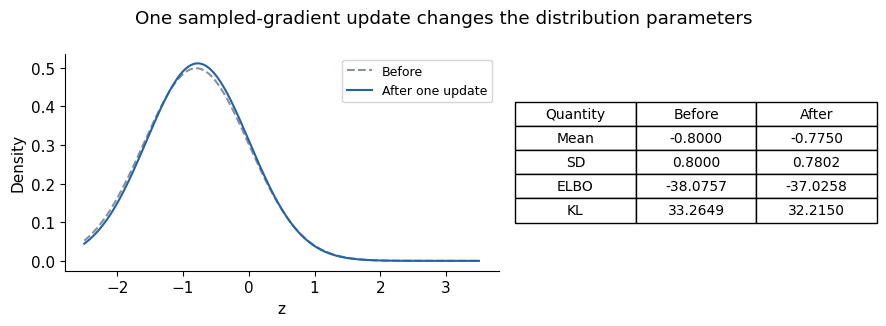

Exact diagnostic values before/after: -38.07570989683519 -37.02579218825379


In [8]:
def scalar_loss(mu, log_sd, observations, response, noise_sd, samples=64):
    q = Normal(mu, log_sd.exp())
    z = q.rsample((samples,))                     # S parameter samples
    predicted = response(z)                      # S predicted sensor means
    log_likelihood = Normal(predicted[:,None], noise_sd).log_prob(observations).sum(-1)
    log_joint = log_likelihood + prior.log_prob(z)
    elbo = (log_joint - q.log_prob(z)).mean()       # average over S
    return -elbo

mu = torch.tensor(-0.8, requires_grad=True)
log_sd = torch.tensor(math.log(.8), requires_grad=True)
optimizer = torch.optim.Adam([mu,log_sd], lr=.025)
before_step=elbo_diagnostics(mu.item(),log_sd.exp().item())
optimizer.zero_grad()
loss = scalar_loss(mu, log_sd, x_obs, lambda z: z, noise_sd)   # identity response: h(z) = z
loss.backward()
print('Gradients [mu, log SD]:', mu.grad.item(),log_sd.grad.item())
optimizer.step()
print('After one step:',mu.item(),log_sd.exp().item())
after_step=elbo_diagnostics(mu.item(),log_sd.exp().item())
fig,(ax,tabax)=plt.subplots(1,2,figsize=(9,3.3),gridspec_kw={'width_ratios':[1.2,1]})
ax.plot(grid,pdf(grid,before_step['mu'],before_step['sd']),'--',color=GRAY,label='Before')
ax.plot(grid,pdf(grid,after_step['mu'],after_step['sd']),color=BLUE,label='After one update')
ax.set(xlabel='z',ylabel='Density');ax.legend(fontsize=9)
tabax.axis('off')
table=tabax.table(cellText=[[label,f"{before_step[key]:.4f}",f"{after_step[key]:.4f}"]
 for label,key in [('Mean','mu'),('SD','sd'),('ELBO','elbo'),('KL','kl')]],
 colLabels=['Quantity','Before','After'],loc='center',cellLoc='center')
table.auto_set_font_size(False);table.set_fontsize(10);table.scale(1,1.7)
fig.suptitle('One sampled-gradient update changes the distribution parameters')
fig.tight_layout();savefig('first_update');plt.show()
print('Exact diagnostic values before/after:',before_step['elbo'],after_step['elbo'])
reveal('Must every sampled-gradient step improve the exact ELBO?',
       'No. A stochastic gradient is noisy. Inspect its trend over multiple updates and use appropriate optimization settings.')


## 5. Fit, inspect, and use the approximation · Slides 9–11 · *Pipeline: Update → Use*
Repeat the same update. Record the distribution before training and at intervals. The exact Gaussian posterior is used only to evaluate accuracy afterwards.

For this model we can also evaluate the ELBO analytically for a clean diagnostic trace:
$$\mathbb E_q\log p(\mathbf x\mid z)
=-\frac N2\log(2\pi\sigma_\epsilon^2)-\frac{\sum_n(x_n-\mu)^2+N\sigma^2}{2\sigma_\epsilon^2}.$$
Subtract $\mathrm{KL}(\mathcal N(\mu,\sigma^2)\|\mathcal N(0,1))=\tfrac12(\mu^2+\sigma^2-1-2\log \sigma)$. This diagnostic is not the training loss used below.

The history below includes updates 0, 1, 2, 5 and 10 so you can pause before the fit changes substantially. Later frames are more widely spaced. The clean diagnostic ELBO and evidence line are for checking; the optimizer uses sampled gradients.

**Pause and predict (slide 10):** what does each interval describe: the fixed unknown $z$ or a future noisy reading?

<details><summary>Answer</summary>The credible interval [0.56, 1.49] (from samples of z) describes the fixed unknown z and shrinks with more readings. The predictive interval [−0.24, 2.29] (from x* = z + ε*) describes the next reading; it also contains the sensor noise and never shrinks below about ±1.96·σ<sub>ε</sub> = ±1.18.</details>

**Checks (slide 11):** the clean ELBO trace and the exact posterior answer *convergence* and *accuracy* for this toy problem only; in a real problem use repeated runs, richer families and predictive checks.

In [9]:
def train_scalar(observations, response, noise_sd, steps=1000, seed=7):
    torch.manual_seed(seed)
    m = torch.tensor(-.8, requires_grad=True)
    r = torch.tensor(math.log(.8), requires_grad=True)
    opt = torch.optim.Adam([m,r],lr=.025)
    history=[(0,m.item(),r.exp().item())]
    for t in range(steps):
        opt.zero_grad()
        loss=scalar_loss(m,r,observations,response,noise_sd)
        loss.backward(); opt.step()
        if (t+1) in [1,2,5,10,20] or (t+1)%40==0: history.append((t+1,m.item(),r.exp().item()))
    return m.detach(),r.detach(),np.array(history)

m_fit,r_fit,hist = train_scalar(x_obs,lambda z:z,noise_sd)
def exact_elbo(m,s):
    ll=-N/2*np.log(2*np.pi*noise_sd**2)-(np.sum((x_obs.numpy()-m)**2)+N*s*s)/(2*noise_sd**2)
    return ll-.5*(m*m+s*s-1-2*np.log(s))
fig,(ax,ax2)=plt.subplots(1,2,figsize=(10,3.4))
trace=np.array([exact_elbo(m,s) for _,m,s in hist])
def training_frame(k):
    ax.clear();ax2.clear();t,m,s=hist[k]
    ax.plot(grid,pdf(grid,exact_mu,exact_sd),'k--',label='Exact check')
    ax.plot(grid,pdf(grid,m,s),color=BLUE,label='q');ax.legend()
    ax.set(xlim=(-2.5,3.5),ylim=(0,2),xlabel='z',ylabel='Density',title=f'Update {int(t)}')
    ax2.plot(hist[:k+1,0],trace[:k+1],color=BLUE,label='Exact ELBO diagnostic')
    ax2.axhline(log_evidence,color='black',ls='--',label='Fixed log evidence')
    ax2.legend(fontsize=8,loc='lower right')
    ax2.set(xlim=(0,1000),ylim=(trace.min()-1,trace.max()+1),xlabel='Update',ylabel='Exact diagnostic ELBO')
training_frame(len(hist)-1);savefig('scalar_fit')
play(fig,training_frame,len(hist))
q_fit=Normal(m_fit,r_fit.exp())
print(f'VI mean={m_fit.item():.4f}, SD={r_fit.exp().item():.4f}')
print(f'Exact mean={exact_mu:.4f}, SD={exact_sd:.4f}')
assert abs(m_fit.item()-exact_mu)<.1
assert abs(r_fit.exp().item()-exact_sd)<.06

VI mean=1.0196, SD=0.2361
Exact mean=1.0220, SD=0.2379


Approximate posterior 95% interval: [0.55107852 1.48236914]
Approximate P(z > 1): 0.5368
Future-reading 95% interval: [-0.2251686   2.28178372]


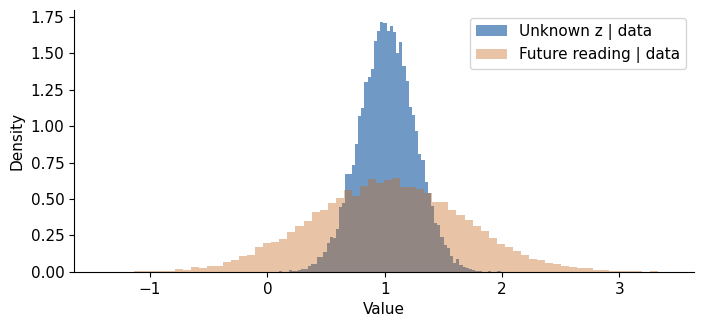

In [10]:
torch.manual_seed(91)
z_draws=q_fit.sample((20000,))
future_x=z_draws + noise_sd*torch.randn_like(z_draws)   # x_* = z + epsilon_*
print('Approximate posterior 95% interval:',torch.quantile(z_draws,torch.tensor([.025,.975])).numpy())
print('Approximate P(z > 1):',float((z_draws>1).double().mean()))
print('Future-reading 95% interval:',torch.quantile(future_x,torch.tensor([.025,.975])).numpy())
fig,ax=plt.subplots(figsize=(8,3.4))
ax.hist(z_draws.numpy(),bins=70,density=True,alpha=.65,color=BLUE,label='Unknown z | data')
ax.hist(future_x.numpy(),bins=70,density=True,alpha=.4,color=ORANGE,label='Future reading | data')
ax.set(xlabel='Value',ylabel='Density');ax.legend();savefig('predictive');plt.show()
reveal('Why is the future-reading distribution wider?', 'It combines uncertainty about z with new measurement noise. More data can reduce uncertainty about z, but do not remove the specified noise of a new reading.')

## 6. A new likelihood, the same code · Slide 12 · *Pipeline: only the Model changes*
Now the sensor response is $h(z)=z+0.2z^3$ and $x_n\mid z\sim\mathcal N(h(z),\sigma_\epsilon^2)$. Keep the same prior and variational family. The log likelihood changes through `response(z)`. The sampling, prior, entropy contribution, differentiation, and optimizer remain the same.

The posterior is generally non-Gaussian. Numerical integration on a fine one-dimensional grid provides a teaching reference. Grid integration is practical here because there is only one unknown; it is not the method used to train $q$.

**Pause and predict (slide 12):** which line of `scalar_loss` changes? How would you predict the next reading?

<details><summary>Reveal the change</summary>The response supplied to the likelihood changes from z to z + 0.2z³. The prior, variational family, sampling and optimizer structure stay the same. Prediction must also use the new response: x* = h(z) + ε*. For the six readings simulated in the next cell (true z = 1, mean 1.19): E[z | x] ≈ 0.94 but E[h(z) | x] ≈ 1.13, so reusing x* = z + ε* would centre the prediction about 0.18 too low.</details>

In [11]:
trapezoid = getattr(np, 'trapezoid', None) or np.trapz   # NumPy >= 2.0 renamed trapz
def nonlinear_response(z): return z+.2*z**3
torch.manual_seed(11)
x_nl=nonlinear_response(torch.tensor(1.0))+noise_sd*torch.randn(6)
m_nl,r_nl,h_nl=train_scalar(x_nl,nonlinear_response,noise_sd,seed=11)
gt=torch.tensor(grid)
log_density=Normal(nonlinear_response(gt)[:,None],noise_sd).log_prob(x_nl).sum(-1)+prior.log_prob(gt)
grid_density=np.exp((log_density-log_density.max()).numpy())
grid_density/=trapezoid(grid_density,grid)
fig,ax=plt.subplots(figsize=(8,3.4))
def nonlinear_frame(k):
    ax.clear();t,m,s=h_nl[k]
    ax.plot(grid,grid_density,'k--',label='Grid reference')
    ax.plot(grid,pdf(grid,m,s),color=BLUE,label='Gaussian q')
    ax.set(xlim=(-1,2.5),ylim=(0,3.6),xlabel='z',ylabel='Density',title=f'Nonlinear sensor: update {int(t)}');ax.legend()
nonlinear_frame(len(h_nl)-1);savefig('nonlinear')
play(fig,nonlinear_frame,len(h_nl))
print('Nonlinear VI:',m_nl.item(),r_nl.exp().item())
print('Grid mean:',trapezoid(grid*grid_density,grid))
reveal('Would replacing h(z) by z squared be harmless?', 'No. The likelihood can then favour both positive and negative values. A single Gaussian can miss a posterior mode. A converged optimizer does not fix a restrictive approximation family.')

Nonlinear VI: 0.9407949814997499 0.15628014491622041
Grid mean: 0.9432158377872291


## 7. Optional extension: minibatches · Slide 15 · *Pipeline: Estimate with data subsampling*
Posterior samples approximate an expectation over unknown parameters. Data minibatches approximate a sum over observations. These are different axes.

For a dataset of size $N$, a uniformly sampled minibatch $B_t$ of size $k$, and $S$ parameter samples:
$$\widehat{\mathcal L}=\frac1S\sum_s\left[\frac Nk\sum_{n\in B_t}\log p(x_n\mid z^{(s)})+\log p(z^{(s)})-\log q(z^{(s)})\right].$$
Only the likelihood sum receives $N/k$. An equivalent per-observation negative ELBO is average batch NLL plus $\mathrm{KL}(q\|p)/N$ when the KL is analytic. Multiplying the **whole** objective by $1/N$ preserves its optimum; changing only one term changes the inference problem.

The following executable check averages the scaled minibatch sums at a fixed candidate $z$. It illustrates unbiasedness of the estimate, not a new training algorithm.

This section can open the BNN lecture. It is not needed to run the full-data scalar and regression examples.


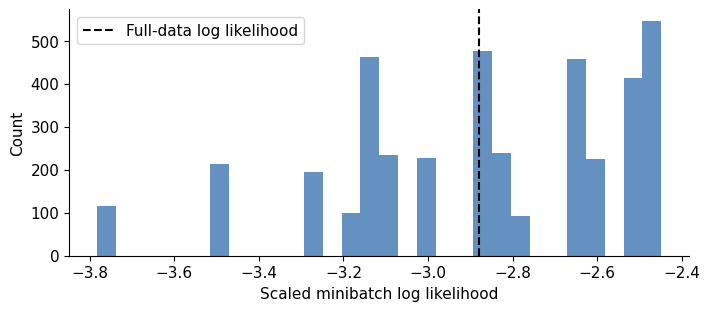

Full sum: -2.8792330121876475 Mean estimate: -2.880198289965425


In [12]:
torch.manual_seed(20)
point=torch.tensor(1.)
per_datum=Normal(point,noise_sd).log_prob(x_obs)
k=2   # minibatch size
idx=torch.randint(0,N,(4000,k))   # 4000 minibatches drawn with replacement
estimates=(N/k)*per_datum[idx].sum(-1)
fig,ax=plt.subplots(figsize=(8,3.2))
ax.hist(estimates.numpy(),bins=30,color=BLUE,alpha=.7)
ax.axvline(per_datum.sum().item(),color='black',ls='--',label='Full-data log likelihood')
ax.set(xlabel='Scaled minibatch log likelihood',ylabel='Count');ax.legend();plt.show()
print('Full sum:',per_datum.sum().item(),'Mean estimate:',estimates.mean().item())

## 8. Two unknowns: regression weights · Slides 13–14 · *Pipeline: new Model and Family*
From here on the data are pairs $D=\{(x_n,y_n)\}_{n=1}^N$: $x_n$ is an input and $y_n$ the observed output. Let $y_n=a x_n+b+\epsilon_n$, $\epsilon_n\sim\mathcal N(0,\sigma_\epsilon^2)$ with $\sigma_\epsilon=0.3$, $\mathbf w=(a,b)$ and independent standard-normal priors. Choose
$$q(\mathbf w)=\prod_{j=1}^2\mathcal N(w_j;\mu_j,\sigma_j^2),\qquad \sigma_j=e^{r_j}.$$
We now optimize four numbers: two means and two log standard deviations. Mean-field refers to independence **under q**, not a claim that the true posterior is independent.

The next helper implements the reusable negative ELBO for any differentiable regression function. We use the analytic Gaussian KL to reduce Monte Carlo noise, but still sample the expected likelihood. `forward` accepts `[S,P]` sampled parameters and returns `[S,k]` predictions for a batch of $k$ inputs. One sampled parameter vector is reused for all inputs in a batch.

In [13]:
def gaussian_kl(mu, log_sd):
    # KL(q || standard Normal prior), summed over weights, including biases.
    return .5*(mu.square()+torch.exp(2*log_sd)-1-2*log_sd).sum()

def regression_loss(mu, log_sd, xb, yb, forward, noise, total_n, samples=16):
    w=mu+log_sd.exp()*torch.randn(samples,mu.numel())
    predictions=forward(w,xb)                       # [S,k]
    expected_batch_nll=-Normal(predictions,noise).log_prob(yb).sum(-1).mean()
    return (total_n/len(xb))*expected_batch_nll+gaussian_kl(mu,log_sd)   # N/k scaling; KL once

def fit_regression(x,y,forward,dimension,noise,steps=1800,seed=30):
    torch.manual_seed(seed)
    mu=(.1*torch.randn(dimension)).requires_grad_()
    log_sd=torch.full((dimension,),-1.5,requires_grad=True)
    opt=torch.optim.Adam([mu,log_sd],lr=.02)
    history=[]
    for t in range(steps+1):
        if t%100==0:
            history.append((t,mu.detach().clone(),log_sd.detach().clone()))
        if t==steps:break
        opt.zero_grad()
        loss=regression_loss(mu,log_sd,x,y,forward,noise,len(x))
        loss.backward();opt.step()
    return mu.detach(),log_sd.detach(),history

def linear_forward(w,x): return w[:,0,None]*x[None,:]+w[:,1,None]
x_lin=torch.linspace(0,2,35)
torch.manual_seed(31)
y_lin=.8*x_lin-.3+.3*torch.randn(len(x_lin))
mu_lin,r_lin,hist_lin=fit_regression(x_lin,y_lin,linear_forward,2,.3)
# Exact posterior and reverse-KL optimal diagonal Gaussian for comparison.
X=torch.stack([x_lin,torch.ones_like(x_lin)],dim=1)
precision=torch.eye(2)+X.T@X/.3**2
cov_exact=torch.linalg.inv(precision)
mean_exact=cov_exact@(X.T@y_lin/.3**2)
sd_mf_opt=precision.diag().rsqrt()
print('VI means:',mu_lin.numpy(),'Exact means:',mean_exact.numpy())
print('VI SDs:',r_lin.exp().numpy(),'Optimal mean-field SDs:',sd_mf_opt.numpy())
print('Exact marginal SDs:',cov_exact.diag().sqrt().numpy())
assert torch.max(torch.abs(mu_lin-mean_exact))<.15

VI means: [ 0.84758759 -0.13570766] Exact means: [ 0.83591929 -0.15310468]
VI SDs: [0.04307076 0.04917551] Optimal mean-field SDs: [0.04355474 0.05064418]
Exact marginal SDs: [0.08474201 0.09853553]


In [14]:
torch.manual_seed(32)
x_plot=torch.linspace(-1,3,150)
eps_lines=torch.randn(12,2)
fig,(ax,ax2)=plt.subplots(1,2,figsize=(10,3.5))
def linear_frame(k):
    ax.clear();ax2.clear();t,m,r=hist_lin[k]
    ws=m+r.exp()*eps_lines
    ax.scatter(ws[:,0],ws[:,1],color=BLUE)
    ax.scatter(*mean_exact.numpy(),color='black',marker='x',label='Exact mean')
    ax.set(xlim=(-.5,1.8),ylim=(-1.5,1),xlabel='Slope a',ylabel='Intercept b',title=f'Weight samples at update {t}');ax.legend()
    ax2.plot(x_plot.numpy(),linear_forward(ws,x_plot).numpy().T,color=BLUE,alpha=.3)
    ax2.scatter(x_lin,y_lin,color=ORANGE,s=12)
    ax2.set(xlim=(-1,3),ylim=(-2,3),xlabel='Input x',ylabel='Output y',title='Each weight sample gives a whole line')
linear_frame(len(hist_lin)-1);savefig('linear')
play(fig,linear_frame,len(hist_lin))
reveal('Why can VI SDs be smaller than exact marginal SDs?', 'This factorized q cannot follow the slope–intercept correlation. For a Gaussian target, the reverse-KL optimal diagonal variance is 1 divided by the corresponding precision diagonal, not the target marginal variance.')

## 9. Bayesian neural network · Slides 14–16 · *Pipeline: all steps, only the Model box changed*
Change $a x+b$ to a neural network $f_{\mathbf w}(x)$. The latent vector $\mathbf w$ now contains **every weight and bias**. With one input, eight tanh hidden units and one output, there are $P=8+8+8+1=25$ parameters. A factorized Gaussian approximation learns 25 means and 25 log standard deviations.

For this regression example:
$$p(\mathbf w)=\mathcal N(\mathbf0,I),\qquad
p(y_n\mid x_n,\mathbf w)=\mathcal N(y_n;f_{\mathbf w}(x_n),\sigma_\epsilon^2).$$
$$-\mathcal L=\mathbb E_{q(\mathbf w)}[-\sum_n\log p(y_n\mid x_n,\mathbf w)]+\mathrm{KL}(q(\mathbf w)\|p(\mathbf w)).$$
`regression_loss` stays unchanged. We change the forward function, dimension and data. Sampling weights gives a deterministic network for that draw. Backpropagation then updates the means and log SDs through the sampled weights. The sampled weights are intermediate tensors, not optimizer parameters.

**Why use a flattened vector here?** It exposes the direct correspondence with scalar VI. A production implementation can wrap the same operations in Bayesian linear layers. Randomly initializing an ordinary network and training it once does not learn a variational distribution.

The core VI lecture can stop after the mapping from scalar unknown to regression weights. The detailed implementation below is retained for the next class.


In [15]:
H=8
P=3*H+1   # number of weights and biases
def bnn_forward(w,x):
    # w:[S,P] with P=25, x:[k]. Broadcast to hidden:[S,k,H].
    w1=w[:,:H]; b1=w[:,H:2*H]; w2=w[:,2*H:3*H]; b2=w[:,-1]
    hidden=torch.tanh(x[None,:,None]*w1[:,None,:]+b1[:,None,:])
    return (hidden*w2[:,None,:]).sum(-1)+b2[:,None]

torch.manual_seed(40)
x_nn=torch.linspace(-2,2,50)
noise_nn=.15
y_nn=torch.sin(1.8*x_nn)+noise_nn*torch.randn(len(x_nn))
mu_nn,r_nn,hist_nn=fit_regression(x_nn,y_nn,bnn_forward,P,noise_nn,steps=3000,seed=41)
print('Random model parameters:',P,'Learned variational parameters:',2*P)
print('All SDs positive:',bool((r_nn.exp()>0).all()))
assert bnn_forward(torch.zeros(4,P),x_nn).shape==(4,len(x_nn))

Random model parameters: 25 Learned variational parameters: 50
All SDs positive: True


**Training animation (slide 16, left).** Keep a fixed set of standard-normal draws for the display so changes in the curves reflect changes in $q$. Training itself uses fresh draws at every step. Each blue curve is one complete network sampled from the current approximation.

Pause midway: are we training eight hidden means only, or distributions over all 25 weights and biases?

In [16]:
x_nn_plot=torch.linspace(-3,3,160)
torch.manual_seed(42)
eps_nn=torch.randn(10,P)
fig,ax=plt.subplots(figsize=(8,3.5))
def bnn_frame(k):
    ax.clear();t,m,r=hist_nn[k]
    curves=bnn_forward(m+r.exp()*eps_nn,x_nn_plot).numpy()
    ax.plot(x_nn_plot.numpy(),curves.T,color=BLUE,alpha=.3)
    ax.scatter(x_nn,y_nn,s=12,color=ORANGE,label='Training data')
    ax.set(xlim=(-3,3),ylim=(-2,2),xlabel='Input x',ylabel='Function value',title=f'10 sampled networks: update {t}')
    ax.legend()
bnn_frame(len(hist_nn)-1);savefig('bnn_functions')
play(fig,bnn_frame,len(hist_nn))

**Prediction uses many sampled networks (slide 16, right).** For $w^{(s)}\sim q$, calculate $f^{(s)}(x_*)$. Their mean estimates $\mathbb E_q[f_w(x_*)]$. In a nonlinear network, this generally differs from $f_{\mathbb E_q[w]}(x_*)$.

Blue bands below are pointwise 95% credible bands for the latent function under $q$. To predict an observation, add independent noise: $y_*^{(s)}=f^{(s)}(x_*)+\epsilon_*^{(s)}$. Orange bands are pointwise approximate posterior predictive intervals, not simultaneous bands and not guaranteed 95% frequentist coverage.

For known constant noise,
$$\operatorname{Var}(y_*\mid x_*,D)\approx\operatorname{Var}_{q(w)}[f_w(x_*)]+\sigma_\epsilon^2.$$
The first component represents weight uncertainty under this approximation. The second represents specified observation noise. A factorized Gaussian can underestimate uncertainty, especially outside the training range. Wide or narrow bands alone do not establish calibration.

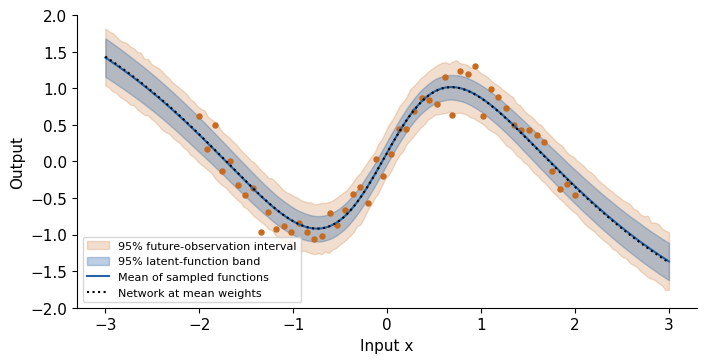

Training RMSE (fit diagnostic only): 0.1883
At x closest to zero: function variance and observation-noise variance: 0.006251307985931872 0.0225


In [17]:
torch.manual_seed(43)
with torch.no_grad():
    weights=mu_nn+r_nn.exp()*torch.randn(2000,P)
    functions=bnn_forward(weights,x_nn_plot)
    observations=functions+noise_nn*torch.randn_like(functions)
    mean_function=functions.mean(0)
    function_band=torch.quantile(functions,torch.tensor([.025,.975]),dim=0)
    predictive_band=torch.quantile(observations,torch.tensor([.025,.975]),dim=0)
    function_at_mean=bnn_forward(mu_nn[None,:],x_nn_plot)[0]
fig,ax=plt.subplots(figsize=(8,3.8))
ax.fill_between(x_nn_plot,*predictive_band.numpy(),color=ORANGE,alpha=.22,label='95% future-observation interval')
ax.fill_between(x_nn_plot,*function_band.numpy(),color=BLUE,alpha=.3,label='95% latent-function band')
ax.plot(x_nn_plot,mean_function,color=BLUE,label='Mean of sampled functions')
ax.plot(x_nn_plot,function_at_mean,'k:',label='Network at mean weights')
ax.scatter(x_nn,y_nn,s=13,color=ORANGE)
ax.set(xlabel='Input x',ylabel='Output',ylim=(-2,2));ax.legend(fontsize=8)
savefig('bnn_predictive');plt.show()
rmse=float(((bnn_forward(weights,x_nn).mean(0)-y_nn)**2).mean().sqrt())
print('Training RMSE (fit diagnostic only):',round(rmse,4))
print('At x closest to zero: function variance and observation-noise variance:',
      float(functions[:,80].var(unbiased=False)),noise_nn**2)
assert rmse<.4
reveal('Can we turn off weight sampling during Bayesian prediction?', 'Using only mean weights gives one function and discards the posterior spread. Average predictions from sampled weights, then include observation noise when predicting future readings.')

**How to adapt this to classification (next lecture).** Keep the weight prior and $q(w)$. Replace the Gaussian likelihood with Bernoulli logits for binary classification or Categorical logits for multiclass classification. For prediction, average sampled probabilities: $\frac1S\sum_s\mathrm{sigmoid}(f_{w^{(s)}}(x))$ or averaged softmax vectors. Applying sigmoid or softmax only to the average logits generally gives a different answer. The likelihood specifies what outputs mean.

**A concrete minibatch training step for this BNN (slide 15):** the original helper already scales the likelihood by $N/k$ and leaves the weight KL unscaled. The following computes gradients without altering the fitted model used above.

In [18]:
torch.manual_seed(44)
batch=torch.randperm(len(x_nn))[:10]   # minibatch B_t with k=10
m_batch=mu_nn.clone().requires_grad_()
r_batch=r_nn.clone().requires_grad_()
loss_batch=regression_loss(m_batch,r_batch,x_nn[batch],y_nn[batch],bnn_forward,
                           noise_nn,total_n=len(x_nn),samples=16)
loss_batch.backward()
print('Finite minibatch gradients:',bool(torch.isfinite(m_batch.grad).all() and torch.isfinite(r_batch.grad).all()))
print('Likelihood multiplier:',len(x_nn)/len(batch),'KL multiplier: 1')

Finite minibatch gradients: True
Likelihood multiplier: 5.0 KL multiplier: 1


## 10. Check understanding · Slide 17
**The recipe for a new problem** (one question per pipeline step): observations and unknowns; $\log p(x,z)$; family $q$ and what it can miss; how samples enter the loss; what the optimizer updates; how samples answer the question.

**Slide 17 questions** (answers in the first four boxes below):
- A. Does the optimizer update $z$, the prior, or $\lambda$?
- B. The ELBO rises from $-20$ to $-10$. Has $q$ improved?
- C. Why is the future-reading interval wider than the interval for $z$?
- D. If the likelihood changes, what code is reused?

**Further exercises.** Work through these before opening the answers.

1. Change the scalar prior SD from 1 to 2. Which parts of the code and analytical check change?
2. Replace the linear sensor with $h(z)=z^2$. Why can multiple initializations give different answers? What would you plot to diagnose this?
3. A BNN has 100 weights including biases. How many variational parameters does this factorized Gaussian use?
4. A batch contains 20 observations from a dataset of 200. Write the total-data negative ELBO estimate using an analytic weight KL.
5. For a future observation, why is the spread of sampled network outputs insufficient?
6. Identify the model, approximation, objective and predictive procedure for binary classification.
7. An optimizer converges, but intervals are too narrow. What problems remain possible?

**Suggested assessment:** provide `regression_loss` and ask students to supply a new likelihood/forward function, state the shapes, identify optimized quantities, and produce a posterior predictive summary. Require an explanation of one limitation.

For the core class, prioritize questions 1, 2, 5 and the model/approximation/objective distinction. Questions 3, 4 and 6 support the next BNN class.


In [19]:
answers=[
('A. What does the optimizer update?','Only lambda = (mu, r), i.e. mu and log_sd. The samples z = mu + exp(r)*eps are recomputed at every step; the prior is part of the model and stays fixed.'),
('B. ELBO from -20 to -10','Yes, for the same model and data: log p(x) is fixed, so the posterior KL fell by exactly 10 nats. Compare averaged, not single noisy, estimates. A higher ELBO means closer to the posterior of this model, not calibrated uncertainty or a correct model.'),
('C. Why the future-reading interval is wider','Var(x*|x) = Var(z|x) + sigma_eps^2 = 0.0566 + 0.36: sd 0.645 versus 0.238. More readings shrink the first term, never the second.'),
('D. What is reused when the likelihood changes','Everything except the model: q, rsample, the sampled ELBO, autodiff, the optimizer loop and sample-based summaries. Only the response/likelihood changes, and predictions must use the new likelihood. Only the Model box of the pipeline changes.'),
('1. Changing the prior','Change prior = Normal(0,2). Update exact posterior precision to 1/4 + N/noise_sd**2, and the KL term in exact_elbo to KL(N(mu, sigma^2) || N(0, 4)) = log(2/sigma) + (sigma^2 + mu^2)/8 - 1/2. For regression, gaussian_kl must also use the new prior variance. The optimizer loop stays the same.'),
('2. Squared response','The likelihood can favour positive and negative z. A unimodal Gaussian and reverse KL can select one mode. Plot the grid reference and fits from several initial means; consider a richer family.'),
('3. Parameter count','200: one mean and one log SD for every weight and bias.'),
('4. Minibatch objective','10 times the Monte Carlo average of the batch NLL sum, plus one analytic KL(q||prior). Equivalently, mean batch NLL plus KL/200.'),
('5. Predictive uncertainty','Sampled networks capture latent-function uncertainty under q. A new observation also contains the likelihood noise.'),
('6. Classification','Specify a weight prior, a factorized Gaussian q, a Bernoulli likelihood with network logits, and expected NLL plus weight KL. Predict by averaging sigmoid probabilities over weight draws.'),
('7. Narrow intervals','Possible causes include an overly restrictive q, missed modes, incorrect loss scaling, poor likelihood/noise assumptions, or optimization at a poor local solution. Check against exact/grid cases, multiple seeds and held-out predictive behaviour.')]
for question,answer in answers: reveal(question,answer)

## Instructor notes and references
**The conceptual repetition is intentional:** unknown scalar $z$, then vector $(a,b)$, then 25 neural-network weights and biases. In every case: specify the probabilistic model, choose $q$, sample through a differentiable transformation, calculate the negative ELBO, update variational parameters, and average predictions.

Suggested pauses (they match the slide questions on slides 4, 6, 9, 10, 12 and 17): after §2 distinguish prior/posterior/q; after §3 identify which normalizing constant disappeared; after §4 identify optimizer parameters; after §6 ask what changed; after §8 connect a weight draw to a complete function; after §9 distinguish the two predictive bands.

The notebook uses fixed priors and known observation noise so model fitting and variational fitting stay separate. Learning a noise parameter or hyperparameter adds another modeling choice. Constrained latent variables require a suitable family or a transformation with the correct density/Jacobian. Reparameterization here assumes continuous differentiable models. Discrete latent variables require other estimators or model-specific treatment.

References:
- Blei, Kucukelbir & McAuliffe (2017), *Variational Inference: A Review for Statisticians*. https://arxiv.org/abs/1601.00670
- Kucukelbir et al. (2017), *Automatic Differentiation Variational Inference*. https://jmlr.org/papers/v18/16-107.html
- Blundell et al. (2015), *Weight Uncertainty in Neural Network*. https://proceedings.mlr.press/v37/blundell15.html
- PyTorch distributions documentation (`sample`, `rsample`, `log_prob`): https://docs.pytorch.org/docs/stable/distributions.html

The small network is an instructional implementation of Gaussian weight VI, not a full reproduction of the prior choices or experimental protocol of Bayes by Backprop.

**New classroom pauses:** compare the wrong-centre, broad and overconcentrated q before showing their scores; read the ELBO graph before its identity; inspect the actual first-step table; predict the likelihood change before the nonlinear example. Use the exact posterior and evidence strictly as teaching diagnostics.
